# HW2_Q1_ADNI Classification

In [3]:
import torch
import numpy as np
import numpy as np
import os
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm
import cv2
import seaborn as sns
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

import tensorflow as tf

import torchvision
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

from PIL import Image
import random

import torch.nn as nn
import gc

import torch.optim as optim
from sklearn.preprocessing import LabelEncoder


# Load ADNI dataset

In [4]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [5]:
image_path_list = []
label_list = []
label = []
image = []

path = '/content/drive/MyDrive/Data/Alzheimer_s_Disease_Neuroimaging_ADNI_Dataset'

for subfoder in tqdm(os.listdir(path)):
    subfoder_path = os.path.join(path,subfoder)
    for img_filename in os.listdir(subfoder_path):
        img_path = os.path.join(subfoder_path, img_filename)
        img = cv2.imread(img_path, cv2.IMREAD_UNCHANGED)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        image.append(img)
        label.append(subfoder)

img_arr = np.array(image)
label_arr = np.array(label)

print('dimension of img_arr', img_arr.shape)
print('dimension of label_arr', label_arr.shape)

for subfoder in tqdm(os.listdir(path)):
    subfoder_path = os.path.join(path,subfoder)
    for img_filename in os.listdir(subfoder_path):
        img_path = os.path.join(subfoder_path, img_filename)
        image_path_list.append(img_path)
        label_list.append(subfoder)


print(image_path_list[200])
print(label_list[200])


100%|██████████| 2/2 [00:29<00:00, 14.99s/it]


dimension of img_arr (1654, 256, 256, 3)
dimension of label_arr (1654,)


100%|██████████| 2/2 [00:00<00:00, 42.03it/s]

/content/drive/MyDrive/Data/Alzheimer_s_Disease_Neuroimaging_ADNI_Dataset/MCI/ADNI_003_S_0908_MR_Axial_T2_Star__br_raw_20140113094422552_14_S210037_I404531.jpg
MCI


<class 'list'>


/tmp/ipykernel_495/2063865340.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  axis = sns.countplot(x = df.label,palette = 'Set1')  #return the Axes obj


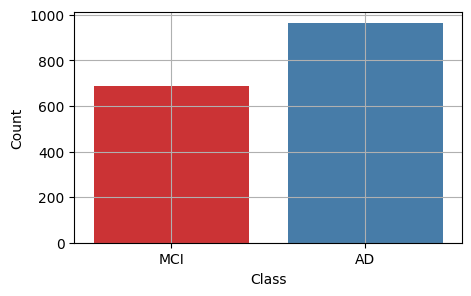

In [6]:
# numbers of each class
df = pd.DataFrame({'image':image , 'label':label})
print(type(image))

plt.figure(figsize= (5,3))
axis = sns.countplot(x = df.label,palette = 'Set1')  #return the Axes obj
axis.set_xlabel('Class')
axis.set_ylabel('Count')
plt.grid(True)

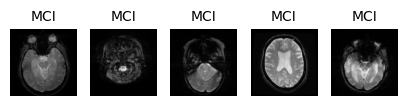

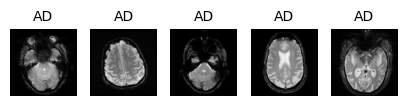

In [7]:
#show 5 pictures from each class
plt.figure(figsize= (5,3))
num_AD = img_arr[label_arr == 'AD'].shape[0]   # 965
num_MCI = img_arr[label_arr == 'MCI'].shape[0]   # 689

for i in range(5):
    n = np.random.randint(0,num_AD)
    plt.subplot(2,5,i+1)
    plt.imshow(img_arr[n])
    plt.title(label_arr[n], fontsize = 10)
    plt.axis('off')
plt.figure(figsize= (5,3))
for i in range(5):
    n = np.random.randint(num_AD + 1 ,num_MCI + num_AD)
    plt.subplot(2,5,i+1)
    plt.imshow(img_arr[n])
    plt.title(label_arr[n], fontsize = 10)
    plt.axis('off')

# Data Augmentation

In [8]:
img_1 = Image.open(image_path_list[1])
print(img_1.size)

(256, 256)


In [9]:
img_2 = cv2.imread(image_path_list[1], cv2.IMREAD_UNCHANGED)
print(img_2.shape)

(256, 256)


In [10]:
def Data_Augmentation(img_path_list , lbl_list):
  augmentation_factors = [
            "horizontal_flip",
            "shearing",
            "shifting",
            "rotation",
            "zooming"
        ]
  augmented_images = []
  augmented_labels = []

  for i in range(len(img_path_list)):
    image_path = img_path_list[i]
    img = Image.open(image_path)
    label = lbl_list[i]

    # Normaize the img
    img = np.array(img)
    img = img/255

    transform_0 = transforms.ToPILImage()
    img = transform_0(img)

    # Resize all images to (64, 64)
    img = img.resize((64, 64))

    augmented_images.append(img)
    augmented_labels.append(label)


    # Offline data augmentation
    for _ in range(4):
        # Randomly choose an augmentation factor
        augmentation_factor = random.choice(augmentation_factors)

        if augmentation_factor == "horizontal_flip":
          img1 = transforms.RandomHorizontalFlip()(img)

        elif augmentation_factor == "shearing":
          img1 = transforms.RandomAffine(degrees=0, shear=20)(img)

        elif augmentation_factor == "shifting":
          img1 = transforms.RandomAffine(degrees=0, translate=(0.2, 0.2))(img)

        elif augmentation_factor == "rotation":
          img1 = transforms.RandomRotation(degrees=45)(img)

        elif augmentation_factor == "zooming":
          img1 = transforms.RandomResizedCrop(size=64, scale=(0.8, 1.2))(img)  #crop and resize

        img2 = img1
        augmented_images.append(img1)
        augmented_labels.append(label)

  return augmented_images, augmented_labels

In [41]:
from sklearn.model_selection import train_test_split

################################## Split original images into train+validation and test sets################################################
X_train_val_paths, X_test_paths, y_train_val, y_test = train_test_split(
    image_path_list,
    label_list,
    test_size=0.05,
    stratify=label_list,
    random_state=42
)

# Split train+validation into training and validation sets
X_train_paths, X_val_paths, y_train, y_val = train_test_split(
    X_train_val_paths,
    y_train_val,
    test_size=0.1,
    stratify=y_train_val,
    random_state=42
)

print("Original dataset split:")
print("Training:", len(X_train_paths))
print("Validation:", len(X_val_paths))
print("Test:", len(X_test_paths))

##################################Apply offline augmentation to training images only#######################################

X_train_aug_list, y_train_aug_list = Data_Augmentation(
    X_train_paths,
    y_train
)

print("Training images after augmentation:", len(X_train_aug_list))
print("Training labels after augmentation:", len(y_train_aug_list))

##################################Preprocessing#######################################
def Prepare_Images(img_path_list):

    prepared_images = []

    for image_path in img_path_list:

        img = Image.open(image_path)

        # Normalize the image
        img = np.array(img)
        img = img / 255

        transform_0 = transforms.ToPILImage()
        img = transform_0(img)

        # Resize all images to (64, 64)
        img = img.resize((64, 64))

        prepared_images.append(img)

    return prepared_images


# Prepare validation and test images without augmentation
X_val_list = Prepare_Images(X_val_paths)
X_test_list = Prepare_Images(X_test_paths)



# Training set (augmented)
data_adni_images_arr = np.array(X_train_aug_list)
data_adni_labels_arr = np.array(y_train_aug_list)

# Validation set (not augmented)
data_adni_images_val_arr = np.array(X_val_list)
data_adni_labels_val_arr = np.array(y_val)

# Test set (not augmented)
data_adni_images_test_arr = np.array(X_test_list)
data_adni_labels_test_arr = np.array(y_test)


print("Final dataset shapes:")
print("Training images:", data_adni_images_arr.shape)
print("Training labels:", data_adni_labels_arr.shape)

print("Validation images:", data_adni_images_val_arr.shape)
print("Validation labels:", data_adni_labels_val_arr.shape)

print("Test images:", data_adni_images_test_arr.shape)
print("Test labels:", data_adni_labels_test_arr.shape)

Original dataset split:
Training: 1413
Validation: 158
Test: 83
Training images after augmentation: 7065
Training labels after augmentation: 7065
Final dataset shapes:
Training images: (7065, 64, 64)
Training labels: (7065,)
Validation images: (158, 64, 64)
Validation labels: (158,)
Test images: (83, 64, 64)
Test labels: (83,)


(7065, 64, 64)


12092

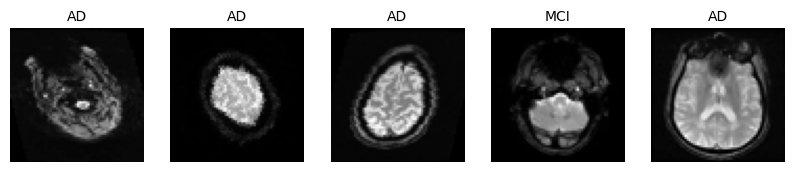

In [42]:
 #show 5 pictures from each class
def plot_5_random(input_image_arr, input_label_arr, num ):
   num_AD = input_image_arr[input_label_arr == 'AD'].shape[0]
   num_MCI = input_image_arr[input_label_arr == 'MCI'].shape[0]
   plt.figure(figsize= (10,6))
   for i in range(5):
     n = np.random.randint(0,num_AD + num_MCI)
     plt.subplot(1,5,i+1)
     plt.imshow(np.squeeze(input_image_arr[n]), cmap = 'gray')
     plt.title(input_label_arr[n], fontsize = 10)
     plt.axis('off')

# data_adni_images_arr2 = np.array(data_adni_images_list)
# data_adni_labels_arr2 = np.array(data_adni_labels_list)
plot_5_random(data_adni_images_arr,data_adni_labels_arr, 5 )
print(data_adni_images_arr.shape)
# del data_adni_images_arr2, data_adni_labels_arr2
gc.collect()

<class 'list'>


/tmp/ipykernel_495/1570860244.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  axis = sns.countplot(x = df.label,palette = 'Set1')  #return the Axes obj


<function gc.collect(generation=2)>

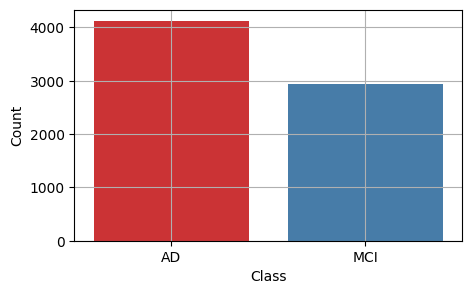

In [43]:
# numbers of each class after data augmentation
data_adni_images_list = list(data_adni_images_arr)
data_adni_labels_list = list(data_adni_labels_arr)

df = pd.DataFrame({'image':data_adni_images_list , 'label':data_adni_labels_list})
print(type(image))

plt.figure(figsize= (5,3))
axis = sns.countplot(x = df.label,palette = 'Set1')  #return the Axes obj
axis.set_xlabel('Class')
axis.set_ylabel('Count')
plt.grid(True)

del df
gc.collect

In [17]:
print(np.shape(data_adni_images_list))
data_adni_images_list = np.expand_dims(data_adni_images_list, axis=1)
print(np.shape(data_adni_images_list))

data_adni_images_arr = np.array(data_adni_images_list)
data_adni_labels_arr = np.array(data_adni_labels_list)


(7065, 64, 64)
(7065, 1, 64, 64)


# Dataset and DataLoader with pytorch

In [44]:
class_to_idx = {
    "AD": 0,
    "MCI": 1
}

In [45]:
class AdniDataset(Dataset):
    def __init__(self, data_array, label_array):
        self.data_array = data_array
        self.label_array = label_array

    def __len__(self):
        return len(self.data_array)

    def __getitem__(self, index):
        data = self.data_array[index]

        # Add channel dimension: (64, 64) -> (1, 64, 64)
        data = torch.tensor(data, dtype=torch.float32).unsqueeze(0)

        label = self.label_array[index]
        label = class_to_idx[label]
        label = torch.tensor(label, dtype=torch.long)

        return data, label


In [46]:
# make train, test, val datasets
train_dataset = AdniDataset(data_adni_images_arr, data_adni_labels_arr)
val_dataset = AdniDataset(data_adni_images_val_arr, data_adni_labels_val_arr)
test_dataset = AdniDataset(data_adni_images_test_arr, data_adni_labels_test_arr)


In [47]:
train_dataset[1]   # is a tupple

(tensor([[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 4., 4.,  ..., 4., 5., 3.],
          [1., 6., 7.,  ..., 7., 9., 5.],
          ...,
          [1., 5., 5.,  ..., 6., 6., 5.],
          [2., 5., 4.,  ..., 5., 5., 5.],
          [0., 2., 2.,  ..., 1., 2., 1.]]]),
 tensor(0))

In [48]:
train_dataset[0]

(tensor([[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 4., 4.,  ..., 4., 5., 3.],
          [1., 6., 7.,  ..., 7., 9., 5.],
          ...,
          [1., 5., 5.,  ..., 6., 6., 5.],
          [2., 5., 4.,  ..., 5., 5., 5.],
          [0., 2., 2.,  ..., 1., 2., 1.]]]),
 tensor(0))

In [49]:
# Create train, test, validation data_loaders
batch_size_model1 = 128
batch_size_model2 = 128
batch_size_model3 = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size_model1, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size_model2, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size_model3, shuffle=False)


sample = next(iter(train_loader))
print(sample[0].shape)


torch.Size([128, 1, 64, 64])


In [56]:
train_sample, train_label = next(iter(train_loader))
val_sample, val_label = next(iter(val_loader))
test_sample, test_label = next(iter(test_loader))

print("Train:", train_sample.shape)
print("Validation:", val_sample.shape)
print("Test:", test_sample.shape)

Train: torch.Size([128, 1, 64, 64])
Validation: torch.Size([128, 1, 64, 64])
Test: torch.Size([83, 1, 64, 64])


In [50]:
sample = next(iter(train_loader))
print(sample[0].shape)
print(np.shape(sample[1]))   # sample[1] is a tuple of labels
print(type(sample[1]))
print(type(sample[1][0]))

torch.Size([128, 1, 64, 64])
torch.Size([128])
<class 'torch.Tensor'>
<class 'torch.Tensor'>


# Part1
# CNN Mode1: Proposed Model

In [51]:
class CNN_Mode_Proposed(nn.Module):
  def __init__(self):
    super().__init__()
    self.feature_extractor = nn.Sequential(
        nn.Conv2d(1,32, kernel_size=3 , padding=1),   # we want to extract 32 feature from this
        #nn.BatchNorm2d(32),
        nn.ReLU(),              # Input: (batch_size, 1, 64, 64), Output: (batch_size, 32, 64, 64)
        #nn.Dropout(0.2),
        nn.Conv2d(32, 32, kernel_size=3 , padding=1),
        #nn.BatchNorm2d(32),
        nn.ReLU(),             # Output: (batch_size, 32, 64, 64)
        nn.MaxPool2d(kernel_size=2, stride=2),
        nn.Conv2d(32, 32, kernel_size=3 , padding=1),
        #nn.BatchNorm2d(32),
        nn.ReLU(),                # Output: (batch_size, 32, 32, 32)
        #nn.Dropout(0.2),
        nn.Conv2d(32, 32, kernel_size=3 , padding=1),
        #nn.BatchNorm2d(32),
        nn.ReLU(),                # Output: (batch_size, 32, 32, 32)
        nn.MaxPool2d(kernel_size=2, stride=2)    # Output: (batch_size, 32, 16, 16)
    )


    self.flat = nn.Flatten()   # Input: (batch_size, 32, 16, 16), Output: (batch_size, 32*16*16)

    self.classifier = nn.Sequential(
        nn.Linear(32*16*16, 128),  # Input: (batch_size, 8192), Output: (batch_size, 128)
        nn.ReLU(),
        nn.Linear(128, 64),
        nn.ReLU(),                 # Input: (batch_size, 128), Output: (batch_size, 64)
        #nn.Dropout(0.2),
        nn.Linear(64, 2),           # Input: (batch_size, 64), Output: (batch_size, 2)
    )

     # Xavier initialization for weights
    for layer in self.feature_extractor:
        if isinstance(layer, nn.Conv2d):
           torch.nn.init.xavier_uniform_(layer.weight,1)
           layer.bias.data.zero_()

    for layer in self.classifier:
        if isinstance(layer, nn.Linear):
            torch.nn.init.xavier_uniform_(layer.weight,1)
            layer.bias.data.zero_()

  def forward(self, x):
    x = self.feature_extractor(x)
    x = self.flat(x)
    x = self.classifier(x)
    return x

In [52]:
model1 = CNN_Mode_Proposed()
sample_2, label_2 = next(iter(val_loader))
sample_2

print(type(sample_2))
print(sample_2.shape)

model1(sample_2.float()).shape

<class 'torch.Tensor'>
torch.Size([128, 1, 64, 64])


torch.Size([128, 2])

# Training model1: Proposed

In [53]:
torch.cuda.is_available()

True

In [54]:
def accuracy_fn(pred,true):
    pred = torch.argmax(pred, dim=1)
    acc = (true == pred).float().mean().item()
    return acc

In [57]:
#batch_size_model1 = 128
epochs = 30
learning_rate = 0.0001


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = CNN_Mode_Proposed().to(device)

# loss function
loss_fn = nn.CrossEntropyLoss()
# optimzier
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

top1_acc_train = []
top1_acc_val = []
loss_avg_train = []
loss_avg_val = []

for epoch in range(1, epochs + 1):
    sum_train_acc_epoch = 0
    sum_val_acc_epoch = 0
    sum_train_loss_epoch = 0
    sum_val_loss_epoch = 0

    model.train()
    mode = "train"

    for batch_idx, (images, labels) in enumerate(train_loader,1):
        images = images.to(device)

        unique_classes = list(set(labels))

        labels = labels.to(device)
        optimizer.zero_grad()    # prevent accumulate the gradients

        labels_pred = model(images.float())
        loss = loss_fn(labels_pred, labels.squeeze())

        loss.backward()
        optimizer.step()   # update the weights

        acc1 = accuracy_fn(labels_pred, labels.squeeze())
        sum_train_acc_epoch += acc1
        sum_train_loss_epoch += loss.detach().item()    # make independent from graph
        if batch_idx % max(1, int(round(len(train_loader)/6))) == 0:   # set how many times show the acc in each epoch
            print(f"At epoch {epoch}, till batch_index {batch_idx}: average accuracy for train ------>  {(sum_train_acc_epoch/batch_idx)*100}")
            print(f"At epoch {epoch}, till batch_index {batch_idx}: average loss for train ---------->  {sum_train_loss_epoch/batch_idx}")
    top1_acc_train.append(sum_train_acc_epoch / batch_idx)
    loss_avg_train.append(sum_train_loss_epoch / batch_idx)


    model.eval()
    mode = "val"

    with torch.no_grad():
        for batch_idx, (images, labels) in enumerate(val_loader,1):
            images = images.to(device)

            unique_classes = list(set(labels))
            labels_encoded = LabelEncoder().fit_transform(labels)  #labels_encoded is a numpy.ndarray with the shape of (256,)
            labels_tensor = torch.from_numpy(labels_encoded).unsqueeze(1)

            labels = labels_tensor.to(device)
            labels_pred = model(images.float())
            loss = loss_fn(labels_pred, labels.squeeze())
            acc1 = accuracy_fn(labels_pred, labels.squeeze())
            sum_val_acc_epoch += acc1
            sum_val_loss_epoch += loss.detach().item()
            if batch_idx % max(1, int(round(len(val_loader)/6))) == 0:
                print(f"At epoch {epoch}, till batch_index {batch_idx}: average accuracy for valid ------>  {(sum_val_acc_epoch/batch_idx)*100}")
                print(f"At epoch {epoch}, till batch_index {batch_idx}: average loss for valid ---------->  {sum_val_loss_epoch/batch_idx}")

        top1_acc_val.append(sum_val_acc_epoch / batch_idx)
        loss_avg_val.append(sum_val_loss_epoch / batch_idx)


At epoch 1, till batch_index 9: average accuracy for train ------>  55.90277777777778
At epoch 1, till batch_index 9: average loss for train ---------->  0.7865727345148722
At epoch 1, till batch_index 18: average accuracy for train ------>  58.50694444444444
At epoch 1, till batch_index 18: average loss for train ---------->  0.7177442875173357
At epoch 1, till batch_index 27: average accuracy for train ------>  60.329861111111114
At epoch 1, till batch_index 27: average loss for train ---------->  0.6905055620052196
At epoch 1, till batch_index 36: average accuracy for train ------>  62.326388888888886
At epoch 1, till batch_index 36: average loss for train ---------->  0.6648218747642305
At epoch 1, till batch_index 45: average accuracy for train ------>  63.645833333333336
At epoch 1, till batch_index 45: average loss for train ---------->  0.6513345599174499
At epoch 1, till batch_index 54: average accuracy for train ------>  64.36631944444444
At epoch 1, till batch_index 54: aver

In [58]:
top1_acc_val

[0.8033854365348816,
 0.8640625178813934,
 0.8679687678813934,
 0.9130208492279053,
 0.9375,
 0.953125,
 0.9169270992279053,
 0.9481770992279053,
 0.9609375,
 0.96484375,
 0.953125,
 0.94921875,
 0.97265625,
 0.9609375,
 0.96484375,
 0.9609375,
 0.96484375,
 0.9609375,
 0.9609375,
 0.953125,
 0.96484375,
 0.96484375,
 0.96484375,
 0.95703125,
 0.953125,
 0.95703125,
 0.96484375,
 0.95703125,
 0.96484375,
 0.9609375]

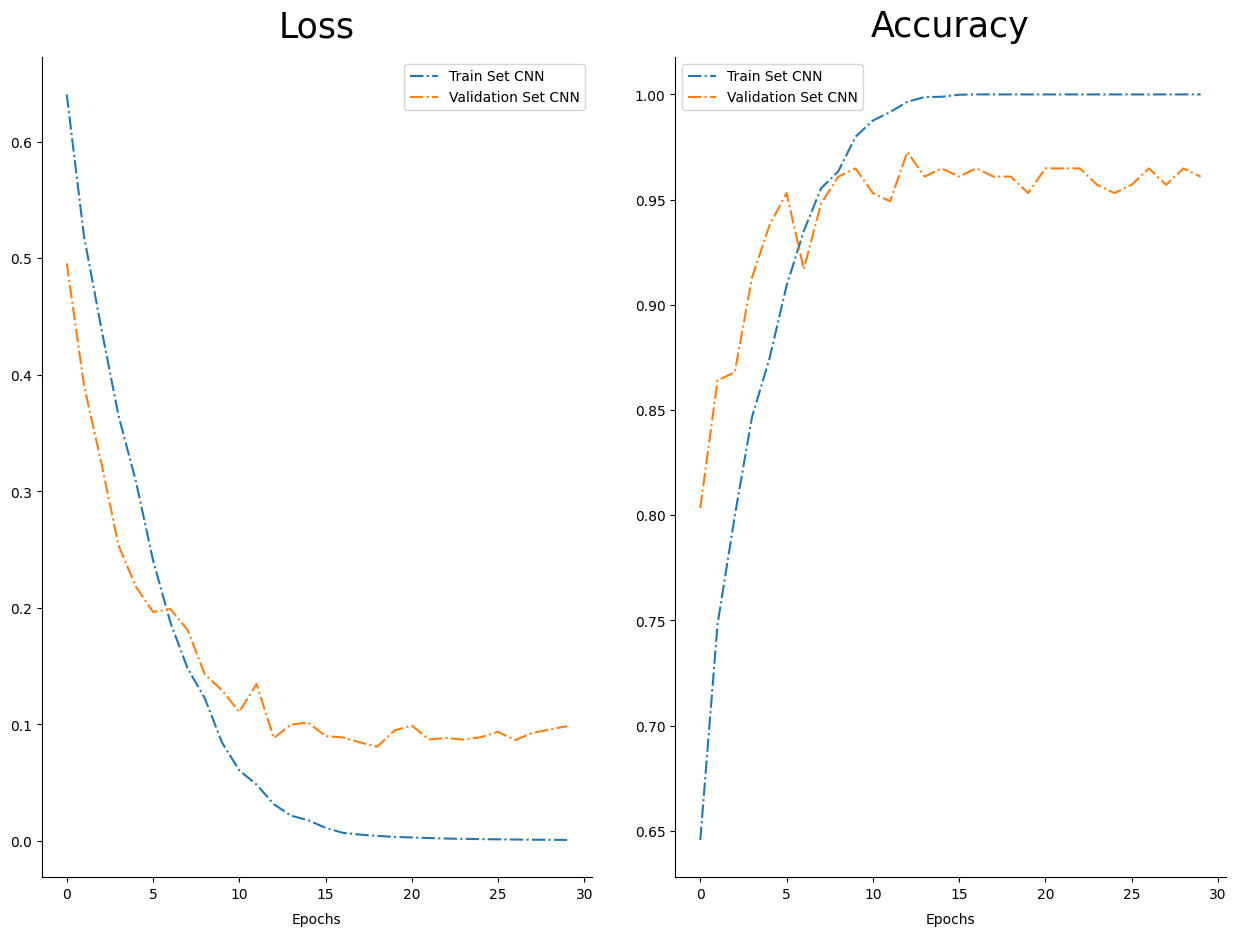

In [59]:
def accloss_plots(train_loss1, test_loss1, train_acc1, test_acc1):
    num_epochs = len(train_loss1)
    plt.figure(figsize=(13, 10))

    # Plot training loss for all sets
    plt.subplot(121)
    plt.plot(train_loss1, '-.', label='Train Set CNN')
    plt.xlabel('Epochs', fontsize=10, labelpad=8)
    plt.title('Loss', fontsize=25, pad=15)
    plt.grid()
    plt.legend()
    sns.despine()

    # Plot testing loss for all sets
    #plt.subplot(223)
    plt.plot(test_loss1, '-.', label='Validation Set CNN')
    plt.xlabel('Epochs', fontsize=10, labelpad=8)
    plt.title('Loss', fontsize=25, pad=15)
    plt.grid()
    plt.legend()
    sns.despine()

    # Plot training accuracy for all sets
    plt.subplot(122)
    plt.plot(train_acc1, '-.', label='Train Set CNN')
    plt.xlabel('Epochs', fontsize=10, labelpad=8)
    plt.title('Accuracy', fontsize=25, pad=15)
    plt.tight_layout(pad=3)
    plt.grid()
    plt.legend()
    sns.despine()

    # Plot testing accuracy for all sets
    #plt.subplot(224)
    plt.plot(test_acc1, '-.', label='Validation Set CNN')
    plt.xlabel('Epochs', fontsize=10, labelpad=8)
    plt.title('Accuracy', fontsize=25, pad=15)
    plt.tight_layout(pad=3)
    plt.grid()
    plt.legend()
    sns.despine()

    plt.show()

accloss_plots(loss_avg_train, loss_avg_val, top1_acc_train, top1_acc_val)


In [60]:
def eval_test(test_loader, model):

    model.to(device)
    model.eval()

    correct = 0
    total_samples = 0
    total_loss = 0

    scores = []
    labels_list = []

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images.float())

            loss = loss_fn(outputs, labels)

            predicted = torch.argmax(outputs, dim=1)

            correct += (predicted == labels).sum().item()
            total_samples += labels.size(0)

            total_loss += loss.item() * labels.size(0)

            probabilities = torch.softmax(outputs, dim=1)

            scores.extend(probabilities[:, 1].cpu().numpy())
            labels_list.extend(labels.cpu().numpy())

    accuracy = correct / total_samples
    average_loss = total_loss / total_samples

    return accuracy, average_loss, scores, labels_list

In [61]:
# Test Proposed Model
test_acc, test_loss, scores, labels_list = eval_test(test_loader, model)
print(f"Test accuracy for proposed_model: {test_acc * 100}%")
print(f"Test loss for proposed_model: {test_loss}")
len(labels_list)

Test accuracy for proposed_model: 97.59036144578313%
Test loss for proposed_model: 0.07771002501249313


83

# Plot the ROC for Proposed Model

In [62]:
from sklearn.metrics import roc_curve, confusion_matrix, accuracy_score, precision_score, recall_score, roc_auc_score, auc, classification_report

def plot_roc_curve(labels, scores):
    fpr, tpr, _ = roc_curve(labels, scores)
    roc_auc = auc(fpr, tpr)

    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

In [63]:
def calculate_metrics_and_confusion_matrix(labels, scores, threshold=0.5):
    scores = np.array(scores)  # Convert scores to a NumPy array
    # Convert scores to predicted labels based on the threshold
    predicted_labels = np.where(scores >= threshold, 1, 0)

    # Calculate evaluation metrics
    tn, fp, fn, tp = confusion_matrix(labels, predicted_labels).ravel()
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    dcs = 2 * (precision * recall) / (precision + recall)
    auc = roc_auc_score(labels, scores)

    # Generate confusion matrix
    cm = confusion_matrix(labels, predicted_labels)

    # Plot confusion matrix
    plt.figure()
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted Labels")
    plt.ylabel("True Labels")
    plt.show()

    # Print classification report
    print("Classification Report:")
    print(classification_report(labels, predicted_labels))
    print("Confusion Matrix:")
    print(cm)
    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("DCS:", dcs)
    print("AUC:", auc)



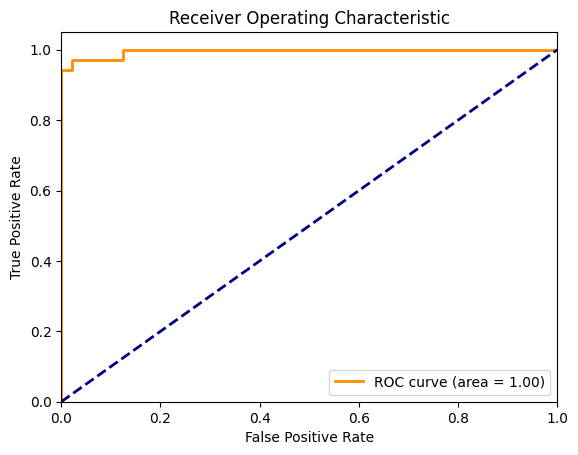

In [64]:
plot_roc_curve(labels_list, scores)

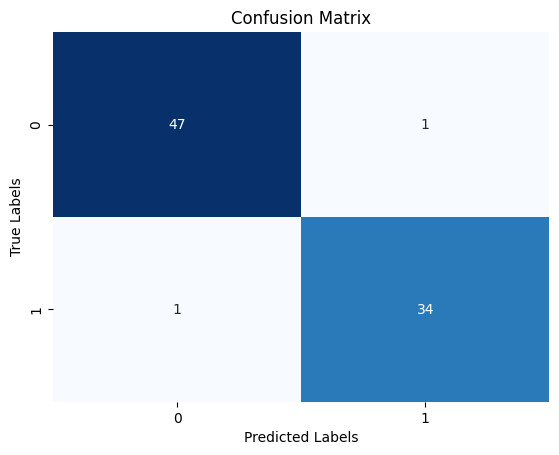

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        48
           1       0.97      0.97      0.97        35

    accuracy                           0.98        83
   macro avg       0.98      0.98      0.98        83
weighted avg       0.98      0.98      0.98        83

Confusion Matrix:
[[47  1]
 [ 1 34]]
Accuracy: 0.9759036144578314
Precision: 0.9714285714285714
Recall: 0.9714285714285714
DCS: 0.9714285714285714
AUC: 0.9958333333333333


In [65]:
calculate_metrics_and_confusion_matrix(labels_list, scores, 0.5)

# Part 2:
# CNN Model: Test Model 1

In [66]:
class CNN_Model_Test1(nn.Module):
  def __init__(self):
    super().__init__()
    self.feature_extractor = nn.Sequential(
        nn.Conv2d(1,32, kernel_size=3 , padding=1),     # we want to extract 32 feature from this
        nn.BatchNorm2d(32),
        nn.ReLU(),                                      # Input: (batch_size, 1, 64, 64), Output: (batch_size, 32, 64, 64)
        #nn.Dropout(0.2),
        nn.MaxPool2d(kernel_size=2, stride=2),          # Output: (batch_size, 32, 32, 32)
        nn.Conv2d(32, 32, kernel_size=3 , padding=1),   # Output: (batch_size, 32, 32, 32)
        nn.BatchNorm2d(32),
        nn.ReLU(),
        #nn.Dropout(0.2),
        nn.MaxPool2d(kernel_size=2, stride=2)    # Output: (batch_size, 32, 16, 16)
    )

    self.flat = nn.Flatten()   # Input: (batch_size, 32, 16, 16), Output: (batch_size, 32*16*16)

    self.classifier = nn.Sequential(
        nn.Linear(32*16*16, 128),  # Input: (batch_size, 8192), Output: (batch_size, 128)
        nn.ReLU(),
        nn.Linear(128, 2),           # Input: (batch_size, 128), Output: (batch_size, 2)
    )


    # Xavier initialization for weights
    for layer in self.feature_extractor:
        if isinstance(layer, nn.Conv2d):
           torch.nn.init.xavier_uniform_(layer.weight,1)
           layer.bias.data.zero_()

    for layer in self.classifier:
        if isinstance(layer, nn.Linear):
            torch.nn.init.xavier_uniform_(layer.weight,1)
            layer.bias.data.zero_()


  def forward(self, x):
    x = self.feature_extractor(x)
    x = self.flat(x)
    x = self.classifier(x)
    return x

In [67]:
model_test1_1 = CNN_Model_Test1()
sample_model_test1_1, label_model_test1_1= next(iter(val_loader))
sample_model_test1_1

print(type(sample_model_test1_1))
print(sample_model_test1_1.shape)

sample_model_test1_1.float().shape

<class 'torch.Tensor'>
torch.Size([128, 1, 64, 64])


torch.Size([128, 1, 64, 64])

# Training model2: Test Model 1

In [70]:
#batch_size_model2 = 128
epochs = 30
learning_rate = 0.0001

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_test1_2 = CNN_Model_Test1().to(device)

# loss function
loss_fn = nn.CrossEntropyLoss()
# optimzier
optimizer_model_test1 = optim.Adam(model_test1_2.parameters(), lr=learning_rate)


acc_train_model_test1 = []
acc_val_model_test1 = []
loss_avg_train_model_test1 = []
loss_avg_val_model_test1 = []


for epoch in range(1, epochs + 1):
    sum_train_acc_epoch = 0
    sum_val_acc_epoch = 0
    sum_train_loss_epoch = 0
    sum_val_loss_epoch = 0

    model_test1_2.train()
    mode = "train"

    for batch_idx, (images, labels) in enumerate(train_loader,1):
        images = images.to(device)

        unique_classes = list(set(labels))
        optimizer_model_test1.zero_grad()    # prevent accumulate the gradients

        labels = labels.to(device)
        labels_pred = model_test1_2(images.float())
        loss = loss_fn(labels_pred, labels.squeeze())

        loss.backward()
        optimizer_model_test1.step()   # update the weights

        acc1 = accuracy_fn(labels_pred, labels.squeeze())
        sum_train_acc_epoch += acc1
        sum_train_loss_epoch += loss.detach().item()    # make independent from graph
        if batch_idx % max(1, int(round(len(train_loader)/6))) == 0:   # set how many times show the acc in each epoch
            print(f"At epoch {epoch}, till batch_index {batch_idx}: average accuracy for train ------>  {(sum_train_acc_epoch/batch_idx)*100}")
            print(f"At epoch {epoch}, till batch_index {batch_idx}: average loss for train ---------->  {sum_train_loss_epoch/batch_idx}")
    acc_train_model_test1.append(sum_train_acc_epoch / batch_idx)
    loss_avg_train_model_test1.append(sum_train_loss_epoch / batch_idx)

    model_test1_2.eval()
    mode = "val"

    with torch.no_grad():
        for batch_idx, (images, labels) in enumerate(val_loader,1):
            images = images.to(device)

            unique_classes = list(set(labels))
            labels_encoded = LabelEncoder().fit_transform(labels)  #labels_encoded is a numpy.ndarray with the shape of (256,)
            labels_tensor = torch.from_numpy(labels_encoded).unsqueeze(1)

            labels = labels_tensor.to(device)
            labels_pred = model_test1_2(images.float())
            loss = loss_fn(labels_pred, labels.squeeze())
            acc1 = accuracy_fn(labels_pred, labels.squeeze())
            sum_val_acc_epoch += acc1
            sum_val_loss_epoch += loss.detach().item()
            if batch_idx % max(1, int(round(len(val_loader)/6))) == 0:
                print(f"At epoch {epoch}, till batch_index {batch_idx}: average accuracy for valid ------>  {(sum_val_acc_epoch/batch_idx)*100}")
                print(f"At epoch {epoch}, till batch_index {batch_idx}: average loss for valid ---------->  {sum_val_loss_epoch/batch_idx}")

        acc_val_model_test1.append(sum_val_acc_epoch / batch_idx)
        loss_avg_val_model_test1.append(sum_val_loss_epoch / len(val_loader))


At epoch 1, till batch_index 9: average accuracy for train ------>  51.5625
At epoch 1, till batch_index 9: average loss for train ---------->  1.0506465368800693
At epoch 1, till batch_index 18: average accuracy for train ------>  55.685763888888886
At epoch 1, till batch_index 18: average loss for train ---------->  0.8949959708584679
At epoch 1, till batch_index 27: average accuracy for train ------>  56.799768518518526
At epoch 1, till batch_index 27: average loss for train ---------->  0.8283757037586637
At epoch 1, till batch_index 36: average accuracy for train ------>  58.35503472222222
At epoch 1, till batch_index 36: average loss for train ---------->  0.7801500360171
At epoch 1, till batch_index 45: average accuracy for train ------>  59.236111111111114
At epoch 1, till batch_index 45: average loss for train ---------->  0.7517696380615234
At epoch 1, till batch_index 54: average accuracy for train ------>  60.35879629629629
At epoch 1, till batch_index 54: average loss for 

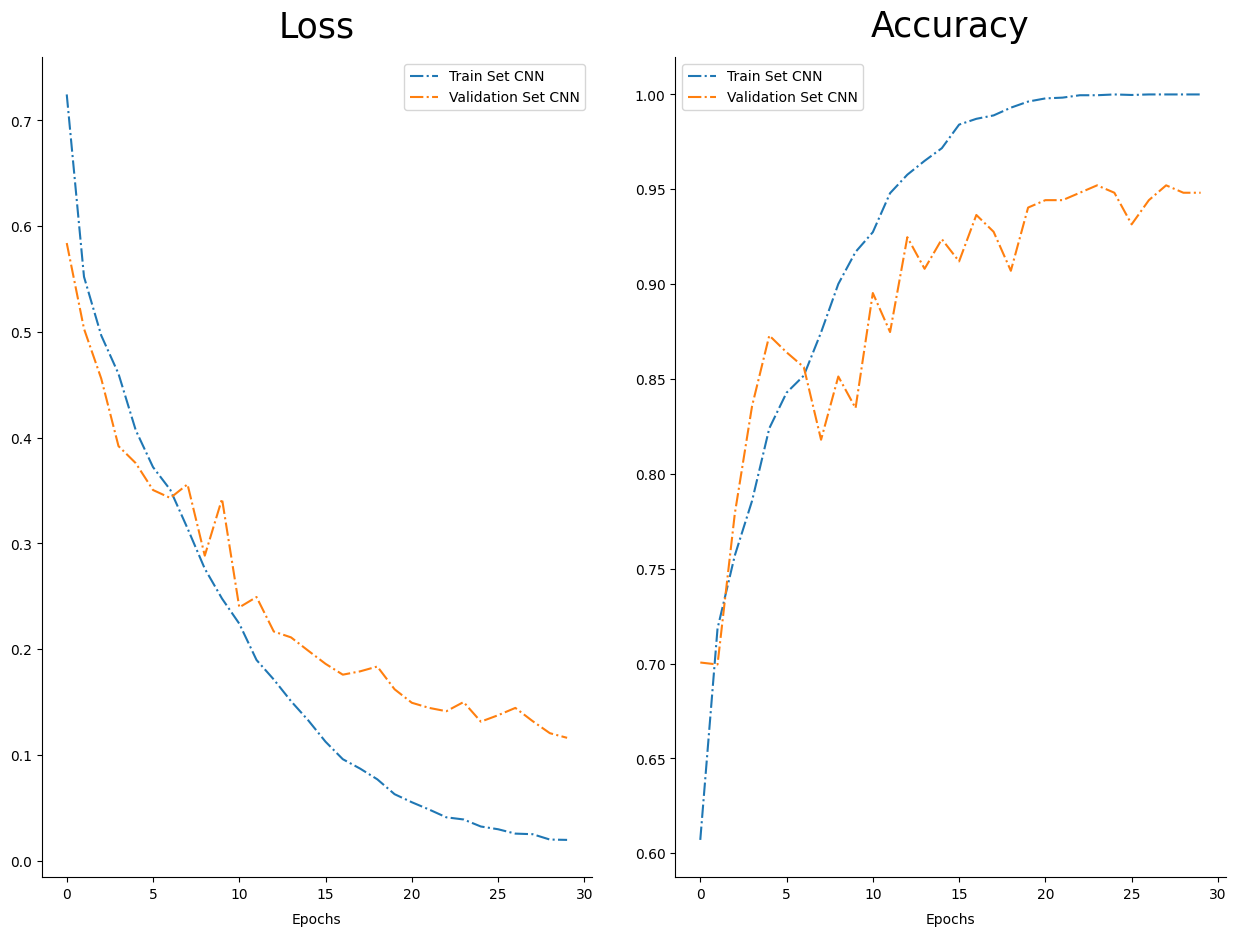

In [71]:
#plot the accuracy and loss curve
accloss_plots(loss_avg_train_model_test1, loss_avg_val_model_test1, acc_train_model_test1, acc_val_model_test1)

In [74]:
# Test Model Test1
test_acc_mode_tets1, test_loss_mode_tets1, scores_mode_tets1, labels_list_mode_tets1 = eval_test(test_loader, model_test1_2)
print(f"Test accuracy for model test1: {test_acc_mode_tets1 * 100}%")
print(f"Test loss for model test1: {test_loss_mode_tets1}")
len(labels_list_mode_tets1)

Test accuracy for model test1: 92.7710843373494%
Test loss for model test1: 0.2186346799135208


83

# Plot the ROC for Model test 1

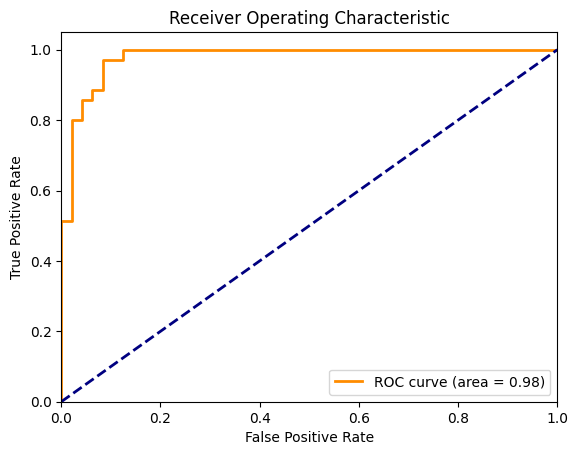

In [75]:
plot_roc_curve(labels_list_mode_tets1, scores_mode_tets1)

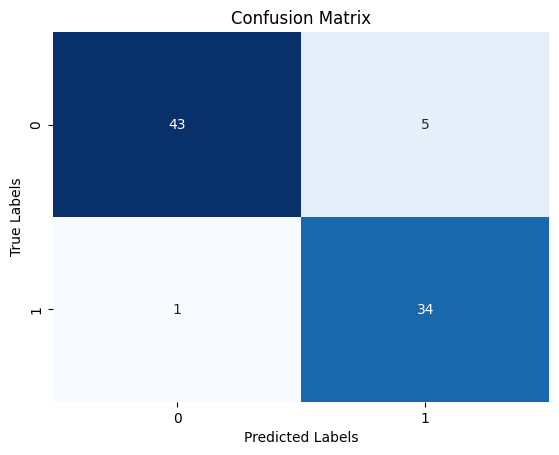

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.90      0.93        48
           1       0.87      0.97      0.92        35

    accuracy                           0.93        83
   macro avg       0.92      0.93      0.93        83
weighted avg       0.93      0.93      0.93        83

Confusion Matrix:
[[43  5]
 [ 1 34]]
Accuracy: 0.927710843373494
Precision: 0.8717948717948718
Recall: 0.9714285714285714
DCS: 0.9189189189189189
AUC: 0.9791666666666666


In [76]:
calculate_metrics_and_confusion_matrix(labels_list_mode_tets1, scores_mode_tets1, 0.5)

# Part3
# CNN Model: Test Model 2

In [78]:
class CNN_Model_Test2(nn.Module):
  def __init__(self):
    super().__init__()
    self.feature_extractor = nn.Sequential(
        nn.Conv2d(1,32, kernel_size=3 , padding=1),     # we want to extract 32 feature from this
        nn.BatchNorm2d(32),
        nn.ReLU(),                                      # Input: (batch_size, 1, 64, 64), Output: (batch_size, 32, 64, 64)
        #nn.Dropout(0.5),
        nn.Conv2d(32,32, kernel_size=3 , padding=1),     # we want to extract 32 feature from this
        nn.BatchNorm2d(32),
        nn.ReLU(),                                      # Input: (batch_size, 32, 64, 64), Output: (batch_size, 32, 64, 64)
        #nn.Dropout(0.5),
        nn.MaxPool2d(kernel_size=2, stride=2),          # Output: (batch_size, 32, 32, 32)
    )

    self.flat = nn.Flatten()   # Input: (batch_size, 32, 16, 16), Output: (batch_size, 32*16*16)

    self.classifier = nn.Sequential(
        nn.Linear(32*32*32, 128),  # Input: (batch_size, 32*32*32), Output: (batch_size, 128)
        nn.ReLU(),
        nn.Linear(128, 64),  # Input: (batch_size, 128), Output: (batch_size, 64)
        nn.ReLU(),
        nn.Linear(64, 2),           # Input: (batch_size, 64), Output: (batch_size, 2)

    )

    # Xavier initialization for weights
    for layer in self.feature_extractor:
        if isinstance(layer, nn.Conv2d):
           torch.nn.init.xavier_uniform_(layer.weight,1)
           layer.bias.data.zero_()

    for layer in self.classifier:
        if isinstance(layer, nn.Linear):
            torch.nn.init.xavier_uniform_(layer.weight,1)
            layer.bias.data.zero_()

  def forward(self, x):
    x = self.feature_extractor(x)
    x = self.flat(x)
    x = self.classifier(x)
    return x

In [79]:
model_test2_1 = CNN_Model_Test2()
sample_model_test2_1, label_model_test2_1= next(iter(val_loader))
sample_model_test2_1

print(type(sample_model_test2_1))
print(sample_model_test2_1.shape)

model_test2_1(sample_model_test2_1.float()).shape

<class 'torch.Tensor'>
torch.Size([128, 1, 64, 64])


torch.Size([128, 2])

# Training model3: Test Model 2

In [80]:
#batch_size_model3 = 128
epochs_2 = 30
learning_rate_2 = 0.0001

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_test2_2 = CNN_Model_Test2().to(device)

# loss function
loss_fn = nn.CrossEntropyLoss()
# optimzier
optimizer_model_test2 = optim.Adam(model_test2_2.parameters(), lr=learning_rate_2)


acc_train_model_test2 = []
acc_val_model_test2 = []
loss_avg_train_model_test2 = []
loss_avg_val_model_test2 = []


for epoch in range(1, epochs_2 + 1):
    sum_train_acc_epoch = 0
    sum_val_acc_epoch = 0
    sum_train_loss_epoch = 0
    sum_val_loss_epoch = 0

    model_test2_2.train()
    mode = "train"

    for batch_idx, (images, labels) in enumerate(train_loader,1):
        images = images.to(device)

        unique_classes = list(set(labels))
        optimizer_model_test2.zero_grad()    # prevent accumulate the gradients

        labels = labels.to(device)
        labels_pred = model_test2_2(images.float())
        loss = loss_fn(labels_pred, labels.squeeze())

        loss.backward()
        optimizer_model_test2.step()   # update the weights

        acc1 = accuracy_fn(labels_pred, labels.squeeze())
        sum_train_acc_epoch += acc1

        sum_train_loss_epoch += loss.detach().item()    # make independent from graph
        if batch_idx % max(1, int(round(len(train_loader)/6))) == 0:   # set how many times show the acc in each epoch
            print(f"At epoch {epoch}, till batch_index {batch_idx}: average accuracy for train ------>  {(sum_train_acc_epoch/batch_idx)*100}")
            print(f"At epoch {epoch}, till batch_index {batch_idx}: average loss for train ---------->  {sum_train_loss_epoch/batch_idx}")
    acc_train_model_test2.append(sum_train_acc_epoch / batch_idx)
    loss_avg_train_model_test2.append(sum_train_loss_epoch / batch_idx)

    model_test2_2.eval()
    mode = "val"

    with torch.no_grad():
        for batch_idx, (images, labels) in enumerate(val_loader,1):
            images = images.to(device)

            unique_classes = list(set(labels))
            labels_encoded = LabelEncoder().fit_transform(labels)  #labels_encoded is a numpy.ndarray with the shape of (256,)
            labels_tensor = torch.from_numpy(labels_encoded).unsqueeze(1)

            labels = labels_tensor.to(device)
            labels_pred = model_test2_2(images.float())
            loss = loss_fn(labels_pred, labels.squeeze())
            acc1 = accuracy_fn(labels_pred, labels.squeeze())
            sum_val_acc_epoch += acc1
            sum_val_loss_epoch += loss.detach().item()
            if batch_idx % max(1, int(round(len(val_loader)/6))) == 0:
                print(f"At epoch {epoch}, till batch_index {batch_idx}: average accuracy for valid ------>  {(sum_val_acc_epoch/batch_idx)*100}")
                print(f"At epoch {epoch}, till batch_index {batch_idx}: average loss for valid ---------->  {sum_val_loss_epoch/batch_idx}")

        acc_val_model_test2.append(sum_val_acc_epoch / batch_idx)
        loss_avg_val_model_test2.append(sum_val_loss_epoch / len(val_loader))


At epoch 1, till batch_index 9: average accuracy for train ------>  56.68402777777778
At epoch 1, till batch_index 9: average loss for train ---------->  1.0323039823108249
At epoch 1, till batch_index 18: average accuracy for train ------>  57.638888888888886
At epoch 1, till batch_index 18: average loss for train ---------->  0.848763171169493
At epoch 1, till batch_index 27: average accuracy for train ------>  58.969907407407405
At epoch 1, till batch_index 27: average loss for train ---------->  0.781994640827179
At epoch 1, till batch_index 36: average accuracy for train ------>  59.396701388888886
At epoch 1, till batch_index 36: average loss for train ---------->  0.7517549759811826
At epoch 1, till batch_index 45: average accuracy for train ------>  60.90277777777777
At epoch 1, till batch_index 45: average loss for train ---------->  0.7234092752138773
At epoch 1, till batch_index 54: average accuracy for train ------>  62.41319444444444
At epoch 1, till batch_index 54: averag

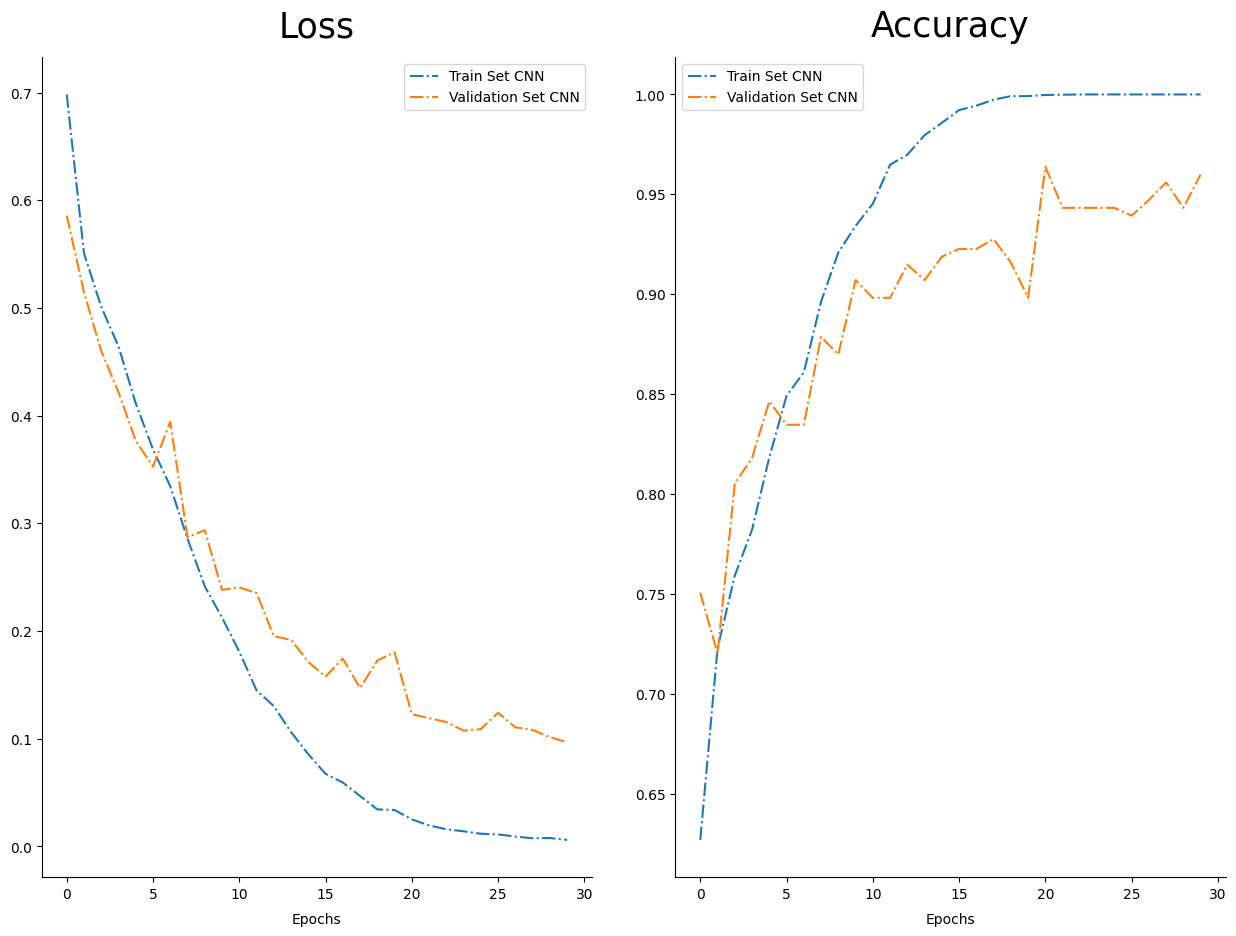

In [81]:
#plot the accuracy and loss curve
accloss_plots(loss_avg_train_model_test2, loss_avg_val_model_test2, acc_train_model_test2, acc_val_model_test2)

In [82]:
# Test Proposed Model
test_acc_mode_tets2, test_loss_mode_tets2, scores_mode_tets2, labels_list_mode_tets2 = eval_test(test_loader, model_test2_2)
print(f"Test accuracy for model test2: {test_acc_mode_tets2 * 100}%")
print(f"Test loss forfor model test2: {test_loss_mode_tets2}")
len(labels_list_mode_tets2)

Test accuracy for model test2: 96.3855421686747%
Test loss forfor model test2: 0.13125279545783997


83

# Plot the ROC for Model test 2

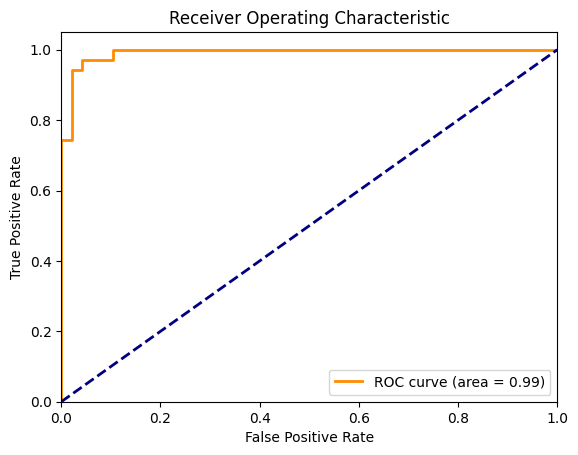

In [83]:
plot_roc_curve(labels_list_mode_tets2, scores_mode_tets2)

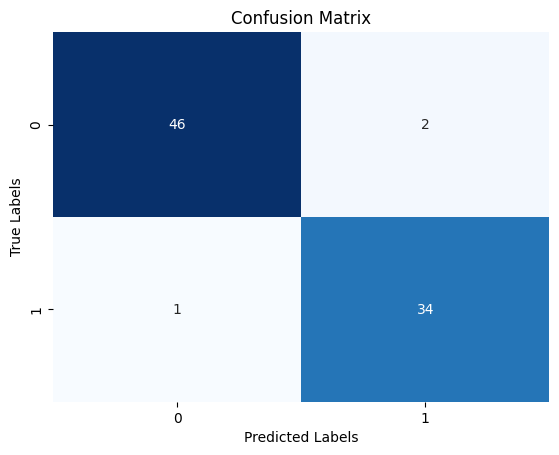

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.96      0.97        48
           1       0.94      0.97      0.96        35

    accuracy                           0.96        83
   macro avg       0.96      0.96      0.96        83
weighted avg       0.96      0.96      0.96        83

Confusion Matrix:
[[46  2]
 [ 1 34]]
Accuracy: 0.963855421686747
Precision: 0.9444444444444444
Recall: 0.9714285714285714
DCS: 0.9577464788732395
AUC: 0.9916666666666667


In [84]:
calculate_metrics_and_confusion_matrix(labels_list_mode_tets2, scores_mode_tets2, 0.5)